# DA2402 Project 3: Assets of Lok Sabha candidates

**Question:** how did declared assets change for candidates who contested 2014, 2019 and 2024, winners against losers?

**States:** Bihar, Maharashtra, Tamil Nadu, Uttar Pradesh.

This notebook walks through the rubric in order. Every table and number below is read from the project files.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
import warnings

warnings.filterwarnings("ignore")   # keeps convergence notes out of the output

pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 200)
pd.set_option("display.max_rows", 100)
DATE = "2026-10-20"

# look in the project folders first, then next to the notebook
FOLDERS = ["../raw", "../raw/lok_sabha_candidate_dfs", "../interim", "../clean", ".", "./merge_v3", "./myneta_prep"]

def find(name):
    for folder in FOLDERS:
        if (Path(folder) / name).exists():
            return Path(folder) / name
    raise FileNotFoundError(name)

## 1. Data collection

| Source | What we took | URL | Collected | How |
|---|---|---|---|---|
| MyNeta (ADR) | Assets, liabilities, age, education, criminal cases, winner flag | https://myneta.info/LokSabha2024/, https://myneta.info/LokSabha2019/, https://myneta.info/ls2014/ | 2026-10-20 | Scraped: `requests` for constituency links, Selenium for candidate tables, OCR for values shown as images |
| OpenCity, 2024 results (from ECI) | Votes, vote share, party | https://data.opencity.in/dataset/parliamentary-elections-2024-results | 2026-10-20 | CSV download in code |
| OpenCity, historical results (from TCPD) | 2014 and 2019 results, by-elections | https://data.opencity.in/dataset/parliamentary-elections-2019 | 2026-10-20 | CSV download in code |
| TCPD Political Parties Index | Party names, abbreviations and types | https://github.com/tcpd/ppi | 2026-10-20 | Downloaded by hand (`TCPD-PPI_1962_2021.csv`, no filters) |

**Notebooks, run end to end in this order:** `scrape_constituency_links` → `scrape_candidates_data` → `Scraping_Missing` → `image_to_text` (OCR) → `01_opencity_datadownload` → `02_opencity_dataprep` → `02b_myneta_dataprep` → `03_merge_opencity_myneta` → `05_dash_dashboard`.

### robots.txt and terms of use

- **OpenCity** robots.txt applies to all crawlers, disallows rating, revision, history pages and the API, and asks for a 10 second crawl delay. We download two CSV files, with a delay. Data licences: 2014/2019 CC BY-NC-SA 4.0 (credit TCPD), 2024 "Other (Public Domain)". Terms and attribution: https://opencity.in/faqs/
- **MyNeta** terms say: *"You must not conduct any systematic or automated data collection activities (including without limitation scraping, data mining, data extraction and data harvesting) on or in relation to this website without ADR's express written consent."* Our scrape was a one-off, rate-limited, for non-commercial coursework, and we credit ADR. We note it as a limitation.

In [2]:
import requests

for url in ["https://data.opencity.in/robots.txt", "https://myneta.info/robots.txt"]:
    try:
        text = requests.get(url, timeout=20, headers={"User-Agent": "DA2402 student project"}).text
        print(f"--- {url}\n{text.strip()[:1500]}\n")
    except Exception as e:
        print(f"--- {url}: could not read ({e})\n")

--- https://data.opencity.in/robots.txt
User-agent: *
Disallow: /dataset/rate/
Disallow: /revision/
Disallow: /dataset/*/history
Disallow: /api/
Crawl-Delay: 10

--- https://myneta.info/robots.txt
User-agent: *
Disallow: /*printer=true
Disallow: /*print=true



### Raw files before any change

Shape and dtypes of each raw file. Column meanings are in the tables under each file.

In [3]:
raw_files = {
    "MyNeta scrape": "candidates_all_years.csv",
    "OpenCity 2024": f"opencity_results2024_{DATE}.csv",
    "OpenCity historical": f"opencity_tcpd_historical_{DATE}.csv",
    "TCPD parties": "TCPD-PPI_1962_2021.csv",
}
raw = {}
for name, f in raw_files.items():
    raw[name] = pd.read_csv(find(f), low_memory=False)
    print(f"{name} ({f}): {raw[name].shape[0]:,} rows x {raw[name].shape[1]} columns")

MyNeta scrape (candidates_all_years.csv): 10,395 rows x 23 columns
OpenCity 2024 (opencity_results2024_2026-10-20.csv): 8,902 rows x 10 columns
OpenCity historical (opencity_tcpd_historical_2026-10-20.csv): 91,669 rows x 45 columns
TCPD parties (TCPD-PPI_1962_2021.csv): 10,153 rows x 21 columns


In [4]:
for name, d in raw.items():
    print(f"\n=== {name}")
    print(d.dtypes.to_string())


=== MyNeta scrape
year                  int64
state                object
state_id              int64
const                object
const_id              int64
sno                   int64
candidate            object
candidate_id          int64
candidate_url        object
is_winner              bool
party                object
criminal_cases        int64
education            object
age                   int64
total_assets         object
asset_link           object
liabilities          object
liability_link       object
constituency_url     object
html_path            object
is_byelection          bool
bye_election_date    object
election_date        object

=== OpenCity 2024
State           object
PC No            int64
PC Name         object
Sl no            int64
Candidate       object
Party           object
EVM Votes       object
Postal Votes    object
Total Votes     object
Vote Share      object

=== OpenCity historical
State_Name                 object
Assembly_No                 i

**MyNeta scrape** (`candidates_all_years.csv`), columns kept

| Column | Meaning |
|---|---|
| year | Election year |
| state, const | State and constituency name as on MyNeta |
| sno | Row number on the constituency page |
| candidate, party | Candidate name and party |
| is_winner | Won the seat |
| criminal_cases | Criminal cases declared |
| education, age | Highest education and age declared |
| total_assets, liabilities | Amounts as text, e.g. `Rs 1,60,59,806 ~ 1 Crore+`; empty when shown as an image |
| asset_link, liability_link | Image link when the amount was shown as a picture (used for OCR) |
| is_byelection, election_date, bye_election_date | Type and date of the election |

**OpenCity 2024** (`opencity_results2024_`), columns kept: `State`, `PC No`, `PC Name` (seat number and name), `Candidate`, `Party` (full name), `Total Votes` (EVM + postal), `Vote Share` (% of valid votes, stored as text).

**OpenCity historical** (`opencity_tcpd_historical_`), columns kept: `State_Name`, `Constituency_No`, `Constituency_Name`, `Year`, `Poll_No` (0 = general election, 1+ = by-election), `Candidate`, `Sex`, `Party` (short code), `Position`, `Votes`, `Vote_Share_Percentage`, `Margin`, `Constituency_Type` (GEN/SC/ST), `Incumbent`, `Turncoat`, `Electors`.

**TCPD parties**, columns kept: `Party_ID`, `Party_Name`, `Frequent_Abbreviation`, `Last_Abbreviation`, `Abbreviations`, `Party_Type`, `Assembly`, `State_Name`, `Last_Year`, `Candidates_Contested`.

## 2. Data storage

- **Folders:** `raw/` (downloads and scrapes, never edited), `interim/` (year-wise extracts, OCR output), `clean/` (final tables, dictionaries, logs).
- **Format: CSV.** About 10,000 rows per table, small enough that Parquet or SQLite give no real gain; CSV opens in Excel and any tool. CSV does not keep column types, so each clean file is read back with a type map and checked (below).

In [5]:
# what is in each folder (works when run from the notebooks folder)
for folder in ["../raw", "../interim", "../clean"]:
    p = Path(folder)
    if p.is_dir():
        print(folder, sorted(f.name for f in p.iterdir())[:30])

../raw ['.DS_Store', 'lok_sabha_candidate_dfs', 'lok_sabha_constituencies', 'lok_sabha_html', 'opencity_results2024_2026-10-20.csv', 'opencity_tcpd_historical_2026-10-20.csv']
../interim ['.DS_Store', 'TCPD-PPI_1962_2021.csv', 'candidate_processing_audit.csv', 'candidates_processed.csv', 'image_ocr_checkpoint.csv', 'opencity_byelections_2014_onwards.csv', 'opencity_electiondata_2014.csv', 'opencity_electiondata_2019.csv', 'opencity_electiondata_2024.csv']
../clean ['merged_all_2026-10-20.csv', 'merged_all_data_dictionary_2026-10-20.csv', 'merged_byelection_2026-10-20.csv', 'merged_general_2026-10-20.csv', 'merged_unmatched_myneta_2026-10-20.csv', 'myneta_candidates_clean_2026-10-20.csv', 'myneta_cleaning_log_2026-10-20.csv', 'myneta_data_dictionary_2026-10-20.csv', 'opencity_results_clean_2026-10-20.csv', 'opencity_results_cleaning_log_2026-10-20.csv', 'opencity_results_data_dictionary_2026-10-20.csv', 'party_map_2026-10-20.csv']


### Data dictionaries

In [6]:
dictionaries = {
    "OpenCity clean": f"opencity_results_data_dictionary_{DATE}.csv",
    "MyNeta clean": f"myneta_data_dictionary_{DATE}.csv",
    "Merged (final table)": f"merged_all_data_dictionary_{DATE}.csv",
}
for name, f in dictionaries.items():
    print(f"\n=== {name} ({f})")
    display(pd.read_csv(find(f)))


=== OpenCity clean (opencity_results_data_dictionary_2026-10-20.csv)


,column,dtype,unit,source,allowed_range,description
0,State,str,name,OpenCity (TCPD / ECI),"one of Bihar, Maharashtra, Uttar Pradesh, Tamil Nadu",State of the constituency
1,Constituency_No,int,number,OpenCity (TCPD / ECI),1 to 80,Parliamentary constituency number within the state
2,Constituency_Name,str,name,OpenCity (TCPD),"207 distinct (State, name) pairs","Constituency name, upper case, one spelling per seat"
3,Constituency_Type,str,category,OpenCity (TCPD); 2024 copied from 2019,"GEN, SC, ST",Reserved status of the seat
4,Year,int,year,OpenCity,"2014, 2019, 2024",Election year (general election only)
5,Person_ID,int,id,derived (name matching),>= 0,Same value for the same person across years (matching rule in Step 9)
6,Candidate,str,name,OpenCity (TCPD / ECI),non-empty,"Candidate name, upper case, no dots or titles"
7,Candidate_Key,str,name,derived,non-empty,"Words of the name in alphabetical order, used for matching"
8,Namesake_In_Seat,bool,flag,derived,True / False,Another candidate in the same seat and year has the same Candidate_Key
9,Party,str,code,OpenCity; 2024 mapped by hand,"short code, OTHER for small 2024 parties",Party code



=== MyNeta clean (myneta_data_dictionary_2026-10-20.csv)


,column,dtype,unit,source,allowed_range,description
0,year,int,year,MyNeta,"2014, 2019, 2024",General election the row belongs to (by-elections carry the year of the general election before them)
1,state,str,name,MyNeta,"BIHAR, MAHARASHTRA, TAMIL NADU, UTTAR PRADESH","State of the constituency, upper case"
2,const,str,name,MyNeta,non-empty,Constituency name as on MyNeta
3,sno,int,number,MyNeta,>= 1,Row number on the MyNeta constituency page
4,candidate,str,name,MyNeta,non-empty,Candidate name as on MyNeta
5,party,str,name,MyNeta; spellings unified (Step 2),"non-empty, IND = independent",Party of the candidate
6,is_winner,bool,flag,MyNeta,True / False,Candidate won this election
7,is_byelection,bool,flag,MyNeta,True / False,Row is from a by-election
8,election_date,date,date,MyNeta,2014 to 2024; empty for by-elections,Polling date of the general election
9,bye_election_date,date,date,MyNeta,2014 to 2024; empty for general elections,Polling date of the by-election



=== Merged (final table) (merged_all_data_dictionary_2026-10-20.csv)


,column,dtype,unit,source,allowed_range,description
0,OC_File,str,name,derived,"opencity_results_clean, opencity_byelections_2014_onwards",Which OpenCity file the row comes from
1,OC_Row,Int64,row number,derived,0 to 10377,"Row number in that OpenCity file, to trace the row back"
2,MN_Row,Int64,row number,derived,0 to 10394; empty if no MyNeta match,"Row number in myneta_candidates_clean, to trace the row back"
3,State,str,name,OpenCity,"Bihar, Maharashtra, Tamil Nadu, Uttar Pradesh",State of the seat
4,Constituency_No,Int64,number,OpenCity,1 to 80,"Seat number within the state; with State, the seat key across years"
5,Constituency_Name,str,name,OpenCity,one spelling per seat,"Seat name, for reading only"
6,Constituency_Type,str,category,OpenCity (TCPD),"GEN, SC, ST",Reserved status of the seat
7,Term,Int64,year,derived,"2014, 2019, 2024","General election the row belongs to; by-elections go to the term they fall in (up to 2018 = 2014, after = 2019)"
8,Election_Year,Int64,year,OpenCity,"2014, 2018, 2019, 2020, 2021, 2024",Year the vote took place
9,Is_ByElection,bool,flag,derived,True / False,Row is from a by-election


### Read back with types and check

In [7]:
# read the final table with an explicit type map and check every column came back as expected
merged_types = {
    "OC_File": "string", "OC_Row": "Int64", "MN_Row": "Int64", "State": "string", "Constituency_No": "Int64",
    "Constituency_Name": "string", "Constituency_Type": "string", "Term": "Int64", "Election_Year": "Int64",
    "Is_ByElection": "bool", "Bye_Year": "Int64", "Person_ID": "Int64", "Candidate": "string", "Candidate_Key": "string",
    "Namesake_In_Seat": "boolean", "Sex": "string", "Incumbent": "boolean", "Party": "string", "Party_Full": "string",
    "Party_ID": "Int64", "Party_Canonical": "string", "Party_Type": "string", "Party_Method": "string", "Party_Group": "string",
    "Position": "Int64", "Winner": "bool", "Votes": "Int64", "Vote_Share_Percentage": "float64", "Margin": "Int64",
    "Seat_Valid_Votes": "Int64", "MN_Candidate": "string", "MN_Party": "string", "MN_Education": "string", "MN_Age": "Int64",
    "MN_Criminal_Cases": "Int64", "Assets_Rs": "float64", "Liabilities_Rs": "float64", "Assets_Status": "string",
    "Liabilities_Status": "string", "Assets_Nil": "boolean", "Has_MyNeta": "bool", "Has_Assets": "bool",
    "Match_Rule": "Int64", "Match_Score": "float64",
}
merged = pd.read_csv(find(f"merged_all_{DATE}.csv"), dtype=merged_types)
wrong = [c for c, t in merged_types.items() if str(merged[c].dtype) != t]
print("rows x columns:", merged.shape, "| columns with an unexpected type:", wrong or "none")

rows x columns: (10512, 44) | columns with an unexpected type: none


## 3. Data cleaning

### Cleaning logs
One line per step with counts before and after. The `note` says what the counts measure.

In [8]:
for name, f in {"OpenCity": f"opencity_results_cleaning_log_{DATE}.csv", "MyNeta": f"myneta_cleaning_log_{DATE}.csv"}.items():
    print(f"\n=== {name} ({f})")
    display(pd.read_csv(find(f)))


=== OpenCity (opencity_results_cleaning_log_2026-10-20.csv)


,year,step,count_before,count_after,rows_affected,note
0,2014,state names: underscore to space,4010,0,4010,Underscores in TCPD state names replaced with spaces to match ECI; counts = rows with '_' in State
1,2019,state names: underscore to space,3447,0,3447,Underscores in TCPD state names replaced with spaces to match ECI; counts = rows with '_' in State
2,2014,keep four states,8843,3868,4975,"Kept Bihar, Maharashtra, UP, Tamil Nadu; counts = rows"
3,2019,keep four states,8613,3545,5068,"Kept Bihar, Maharashtra, UP, Tamil Nadu; counts = rows"
4,2024,keep four states,8902,3626,5276,"Kept Bihar, Maharashtra, UP, Tamil Nadu; counts = rows"
5,2014,drop by-election rows (Poll_No > 0),3868,3844,24,By-election rows removed (Poll_No > 0); they made 4 seat-years' vote shares add up to ~200; counts = rows
6,2019,drop by-election rows (Poll_No > 0),3545,3528,17,By-election rows removed (Poll_No > 0); they made 4 seat-years' vote shares add up to ~200; counts = rows
7,all,one name per seat,216,207,9,"2024 constituency spellings replaced with 2019 ones, counts = distinct (State, name) pairs over three years"
8,2024,Total Votes: text to number,3626,0,3626,2024 df stores Total Votes as text; converted to numbers in Votes; counts = text cells
9,2024,Vote Share: text to number,3626,0,3626,2024 df stores Vote Share as text; converted to numbers in Vote_Share_Percentage; counts = text cells



=== MyNeta (myneta_cleaning_log_2026-10-20.csv)


,year,step,count_before,count_after,rows_affected,note
0,all,state: extra spaces and line breaks,0,0,0,"cells with a line break, nbsp or double space"
1,all,const: extra spaces and line breaks,0,0,0,"cells with a line break, nbsp or double space"
2,all,candidate: extra spaces and line breaks,0,0,0,"cells with a line break, nbsp or double space"
3,all,party: extra spaces and line breaks,0,0,0,"cells with a line break, nbsp or double space"
4,all,education: extra spaces and line breaks,0,0,0,"cells with a line break, nbsp or double space"
5,all,total_assets: extra spaces and line breaks,10308,0,10308,"cells with a line break, nbsp or double space"
6,all,liabilities: extra spaces and line breaks,8578,0,8578,"cells with a line break, nbsp or double space"
7,all,"party: same name, different spelling",771,760,11,distinct party names
8,all,exact duplicate rows,0,0,0,rows
9,all,"duplicate keys (year, seat, by-election, sno)",0,0,0,rows; one row per candidate per election


### Inconsistencies fixed (details in the logs above)

- **OpenCity:** state names (`Tamil_Nadu` → `Tamil Nadu`), one spelling per seat, 2024 votes and vote shares stored as text → numbers, double spaces in party names, 2024 party names → the short codes used in 2014/2019, NOTA dropped and positions recomputed without it.
- **MyNeta:** line breaks and non-breaking spaces from OCR, 11 party spellings unified, `Rs ... ~ ... Crore+` text → rupees (checked against the rounded figure), ages under 25 and education `Not Given` → missing, dates → real dates.

### Duplicates

- **Exact duplicates:** none in either source.
- **Within a source:** key = one candidate per seat per election. Two candidates with the same name in one seat are different people (different age, party, assets), so they are flagged, not removed.
- **Same person across years (OpenCity):** one `Person_ID`, linked by name, seat and party; tested against TCPD's own `Contested` column.
- **Across sources (OpenCity ↔ MyNeta):** paired one to one inside each seat and election, strictest rule first. A pair is never made on name alone when the two parties clearly differ.

In [9]:
rules = {1: "same words in the name", 2: "same letters", 3: "initials vs full name", 4: "name similarity ≥ 0.85",
         5: "same party + similarity ≥ 0.70", 6: "last one left, same party", 7: "winner on both sides"}
pairs = merged.dropna(subset=["Match_Rule"])
print(pairs["Match_Rule"].astype(int).map(rules).value_counts().to_string())
both = merged[merged["Has_MyNeta"]]
print(f"\nOpenCity rows matched: {merged['Has_MyNeta'].mean():.1%} | winners matched: {merged.loc[merged['Winner'], 'Has_MyNeta'].sum()} of {merged['Winner'].sum()}")

Match_Rule
same words in the name            9049
name similarity ≥ 0.85             527
same party + similarity ≥ 0.70     196
same letters                       153
initials vs full name              100
last one left, same party           50
winner on both sides                 9

OpenCity rows matched: 95.9% | winners matched: 630 of 633


**Check on the matching:** the winner flag comes independently from both sources. It agrees on every matched pair, which a wrong pairing would break.

### Missing values (MyNeta)

Count and pattern per column, then a logistic regression per gap: is being missing predicted by year, state, winning or assets? The likelihood ratio (LR) test compares that model with one that predicts nothing. A high p means nothing predicts the gap.

In [10]:
mn = pd.read_csv(find(f"myneta_candidates_clean_{DATE}.csv"))
mn_raw = raw["MyNeta scrape"]

counts = pd.DataFrame({
    "asset shown as image": mn_raw["total_assets"].isna(),
    "age": mn["age"].isna(),
    "education": mn["education"].isna(),
    "election_date (general only)": mn["election_date"].isna(),
}).groupby(mn["year"]).sum().T
counts["total"] = counts.sum(axis=1)
counts

year,2014,2019,2024,total
asset shown as image,1170,1021,1069,3260
age,29,12,0,41
education,63,10,8,81
election_date (general only),99,50,18,167


In [11]:
def missing_test(flag, name):
    data = pd.DataFrame({"missing": flag.astype(int), "year": mn["year"], "state": mn["state"],
                         "winner": mn["is_winner"].astype(int), "log_assets": np.log10(mn["assets_rs"] + 1)})
    fit = smf.logit("missing ~ C(year) + C(state) + winner + log_assets", data).fit(disp=0)
    return {"gap": name, "rows": int(flag.sum()), "LR": round(fit.llr, 1), "p": f"{fit.llr_pvalue:.2g}"}

pd.DataFrame([missing_test(mn_raw["total_assets"].isna(), "asset shown as image"),
              missing_test(mn["age"].isna(), "age"),
              missing_test(mn["education"].isna(), "education")])

,gap,rows,LR,p
0,asset shown as image,3260,2.5,0.92
1,age,41,78.7,2.6e-14
2,education,81,138.6,1e-26


| Gap | Mechanism | Why | What we did |
|---|---|---|---|
| Asset/liability shown as image (31%) | MCAR | Every 3rd row on a MyNeta page is an image; nothing predicts it (high p) | Read by OCR, so real values, not imputed |
| Dates | By design | `election_date` is empty only for by-elections and the other way round | Left empty |
| Age (0.4%) | MAR | Predicted by year and state; no winners missing | Left missing |
| Education (0.8%) | MAR, MNAR possible | Predicted by year, state and low assets; people may leave it blank on purpose | Left missing |
| OpenCity sex/incumbent (2014/2019) | By design | Missing only in NOTA rows | NOTA rows dropped |
| OpenCity 2024 sex/incumbent | Structural | Columns not in the 2024 file | Incumbent derived (won in 2019); sex left missing |

**Why no imputation:** the asset gaps were recovered, not filled. Age and education are under 1% of rows, no winner is affected, and the question does not use them. Imputing would invent facts about real people.

### Outliers

| Variable | Method | Flagged | Diagnosis | Action |
|---|---|---|---|---|
| Assets | 1.5 × IQR on log10(assets) | 18 high, 67 low | Match MyNeta's own rounded figure; known rich politicians and small independents | Kept, flagged |
| Criminal cases | Modified z-score > 3.5 on log10(cases) | 2 | Kudankulam protest leaders, hundreds of cases filed | Kept, flagged |
| Age | 1.5 × IQR | 18 (over 80) | Known senior politicians | Kept |
| Votes | Modified z-score on log10(votes) within year and role | see OpenCity log | Every flagged value matches its vote share and the seat total | Kept, flagged |
| Seat size, margin | 1.5 × IQR per year | see OpenCity log | Real large or very close seats | Kept |

Medians and log scales are used in the analysis so a few extreme values do not drive the results.

## 4. Visualisation

The dashboard (`05_dash_dashboard`) has 9 tabs and over 25 plots. Every plot has a title, axis titles with units, a legend where colour carries meaning, and a 1–2 sentence caption with a number. One colour per meaning across all tabs: **amber = winners, blue = losers**, grey for the rest.

| Tab | Plots | Type |
|---|---|---|
| Overview | Median assets by year; winner ÷ loser gap; change in median assets | bivariate |
| Winners vs Losers | Asset histogram; box plot per year | univariate, bivariate |
| Parties | Median winner vs loser per party | bivariate |
| Repeat Candidates | Change in assets (₹ and %); median change; people who ran all three times; one person over time | bivariate |
| States | Median winner and loser by state; 15 richest winners; reserved vs general seats | bivariate |
| Crime | Cases vs win rate; cases vs assets; cases by party | bivariate |
| Education & Age | Assets and win rate by education; assets and age by group | bivariate |
| Data | Candidates per state; match rate; **before vs after cleaning (MyNeta and OpenCity)** | univariate |

### Before and after cleaning

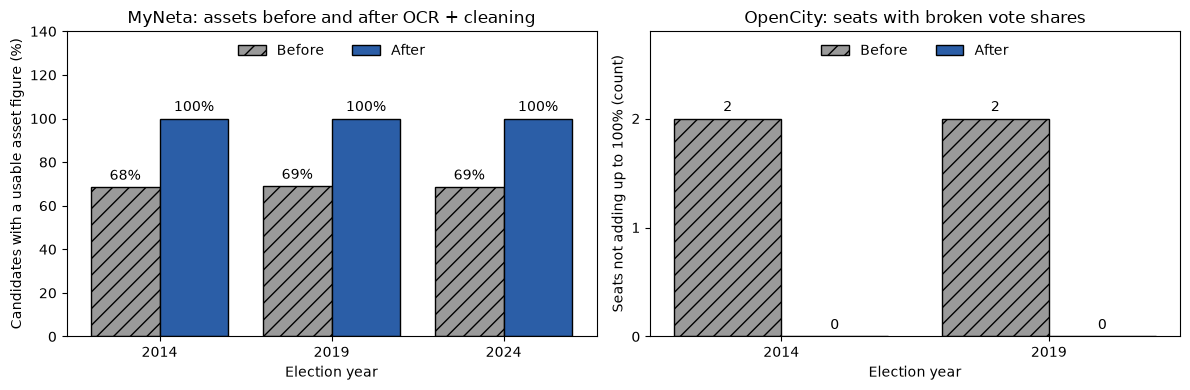

In [12]:
# myneta: share of candidates with a usable asset figure; opencity: seats whose vote shares do not add up to 100%
mn_before = mn_raw["total_assets"].notna().groupby(mn_raw["year"]).mean() * 100
mn_after = mn["assets_rs"].notna().groupby(mn["year"]).mean() * 100

def seats_off(year, general_only):
    h = pd.read_csv(find(f"opencity_electiondata_{year}.csv"), low_memory=False)
    h = h[h["State_Name"].str.replace("_", " ").isin(["Bihar", "Maharashtra", "Uttar Pradesh", "Tamil Nadu"])]
    if general_only:
        h = h[h["Poll_No"] == 0]
    total = h.groupby(["State_Name", "Constituency_No"])["Vote_Share_Percentage"].sum()
    return int(((total - 100).abs() > 0.5).sum())

oc = pd.DataFrame({"before": [seats_off(y, False) for y in [2014, 2019]],
                   "after": [seats_off(y, True) for y in [2014, 2019]]}, index=[2014, 2019])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
x = np.arange(3)
for ax, (b, a, labels, ylabel, title, fmt) in zip(axes, [
        (mn_before.values, mn_after.values, mn_before.index, "Candidates with a usable asset figure (%)", "MyNeta: assets before and after OCR + cleaning", "{:.0f}%"),
        (oc["before"].values, oc["after"].values, oc.index, "Seats not adding up to 100% (count)", "OpenCity: seats with broken vote shares", "{:.0f}")]):
    x = np.arange(len(labels))
    for off, vals, name, colour, hatch in [(-0.2, b, "Before", "#9a9a9a", "//"), (0.2, a, "After", "#2b5ea7", "")]:
        bars = ax.bar(x + off, vals, 0.4, label=name, color=colour, hatch=hatch, edgecolor="black")
        ax.bar_label(bars, [fmt.format(v) for v in vals], padding=3)
    ax.set_xticks(x, labels)
    ax.set_xlabel("Election year")
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.set_ylim(0, max(b.max(), a.max()) * 1.4)
    ax.legend(loc="upper center", ncol=2, frameon=False)
    ax.yaxis.get_major_locator().set_params(integer=True)
plt.tight_layout()
plt.show()

Before cleaning only about **69%** of MyNeta candidates had their assets as text; OCR and parsing bring every year to **100%**. In OpenCity, **4** seats (2 in 2014, 2 in 2019) added up to about 200% because a by-election was stored in the same seat; after removing by-election rows, **0** do. Hatching keeps the bars apart in greyscale.

## 5. Results

General elections only. "Winner" and "loser" mean the result in that election.

In [13]:
g = merged[~merged["Is_ByElection"]].copy()
a = g[g["Assets_Rs"] > 0]
crore = lambda v: round(v / 1e7, 2)

# 1. median declared assets by year
m = a.groupby(["Election_Year", "Winner"])["Assets_Rs"].median().unstack()
result1 = pd.DataFrame({"median winner (₹ cr)": crore(m[True]), "median loser (₹ cr)": crore(m[False]),
                        "winner ÷ loser": (m[True] / m[False]).round(1)})
result1

,median winner (₹ cr),median loser (₹ cr),winner ÷ loser
Election_Year,,,
2014,3.39,0.21,15.9
2019,6.58,0.24,26.9
2024,9.37,0.28,33.8


In [14]:
# 2. the same person in two elections (winner or loser = result at the first one)
p = g.dropna(subset=["Person_ID"]).drop_duplicates(["Person_ID", "Election_Year"])
rows = []
for y0, y1 in [(2014, 2019), (2019, 2024), (2014, 2024)]:
    s = p[p["Election_Year"] == y0][["Person_ID", "Winner", "Assets_Rs"]].merge(
        p[p["Election_Year"] == y1][["Person_ID", "Assets_Rs"]], on="Person_ID", suffixes=("_0", "_1"))
    s = s[(s["Assets_Rs_0"] > 0) & (s["Assets_Rs_1"] > 0)]
    for w, part in s.groupby("Winner"):
        rows.append({"period": f"{y0} → {y1}", "group": "winners" if w else "losers", "people": len(part),
                     "median change (₹ cr)": crore((part["Assets_Rs_1"] - part["Assets_Rs_0"]).median()),
                     "median change (%)": round(100 * (part["Assets_Rs_1"] / part["Assets_Rs_0"] - 1).median()),
                     "got richer (%)": round(100 * (part["Assets_Rs_1"] > part["Assets_Rs_0"]).mean())})
result2 = pd.DataFrame(rows)
result2

,period,group,people,median change (₹ cr),median change (%),got richer (%)
0,2014 → 2019,losers,191,0.33,48,82
1,2014 → 2019,winners,108,3.11,54,94
2,2019 → 2024,losers,189,0.16,44,79
3,2019 → 2024,winners,121,3.35,54,92
4,2014 → 2024,losers,114,0.90,146,91
5,2014 → 2024,winners,72,6.34,129,96


In [15]:
# 3. people who ran in all three elections, by how many times they won
runs = g.dropna(subset=["Person_ID"]).groupby("Person_ID")["Election_Year"].nunique()
three = g[g["Person_ID"].isin(runs[runs == 3].index)]
wins = three.groupby("Person_ID")["Winner"].sum()
group = wins.map(lambda k: "won all 3" if k == 3 else ("never won" if k == 0 else "won 1 or 2"))
result3 = (three[three["Assets_Rs"] > 0].assign(group=three["Person_ID"].map(group))
           .groupby(["group", "Election_Year"])["Assets_Rs"].median().unstack().apply(crore))
result3["people"] = group.value_counts()
result3

Election_Year,2014,2019,2024,people
group,,,,
never won,0.22,0.21,0.43,38
won 1 or 2,3.82,6.59,9.78,76
won all 3,3.60,8.19,14.32,25


In [16]:
# 4. does the richest candidate in a seat win?
g["rank"] = g.groupby(["Election_Year", "State", "Constituency_No"])["Assets_Rs"].rank(ascending=False, method="min")
w = g[g["Winner"] & g["rank"].notna()]
print(f"richest candidate in the seat won: {100 * g.loc[g['rank'] == 1, 'Winner'].mean():.1f}% of seats")
print(f"winners who were among the 5 richest in their seat: {100 * (w['rank'] <= 5).mean():.0f}%")

richest candidate in the seat won: 34.1% of seats
winners who were among the 5 richest in their seat: 94%


**What the results show**

1. **The gap widened.** The median winner declared ₹3.39 cr in 2014 and ₹9.37 cr in 2024; the median loser went from ₹21 lakh to ₹28 lakh. Winners went from about **16×** to **34×** the median loser.
2. **The same people grew at similar rates.** Between 2014 and 2024 the median 2014 winner grew **129%** and the median loser **146%**. In rupees that is **+₹6.34 cr** against **+₹0.90 cr**, because winners start far richer.
3. **Starting wealth sets the path.** People who won all three times went from ₹3.60 cr to ₹14.32 cr; people who never won, from ₹22 lakh to ₹43 lakh.
4. **Money and winning go together.** The richest candidate in a seat wins about a third of the time, and almost every winner is among the five richest in the seat.

## Conclusion

Declared assets of winners rose much faster in rupees than those of losers: the median winner gained about **₹6 cr** over ten years, the median loser under **₹1 cr**, and the winner–loser gap doubled from **16×** to **34×**. But in percentage terms both grew at a similar rate (**129%** vs **146%**). So the data fits **"the rich win"** better than **"winners get richer"**: winners were already far wealthier, and their wealth grew at a normal rate on a much bigger base. The absolute gain was much more nevertheless

## Limitations

- Assets are self-declared and not verified
- Not adjusted for inflation (prices rose roughly 60–70% over the decade).
- Four states only.
- People are linked by name, seat and party, since there is no shared ID; about 4% of OpenCity rows have no MyNeta match, and 3 winners are missing from MyNeta.
- The same-person comparisons cover a few hundred people, a small and unusual group.
- Correlation, not cause: richer candidates may win more, rather than winning making them richer.
- MyNeta's terms do not allow automated collection without ADR's consent (we mark this as a limitation since our course-project is non-commercial work).

## Attributions

**Data**

| Source | Licence |
|---|---|
| MyNeta, Association for Democratic Reforms (from affidavits filed with ECI) | No open licence; terms prohibit automated collection without consent. Used for non-commercial coursework with credit to ADR |
| OpenCity, 2014/2019 results from the Trivedi Centre for Political Data (TCPD), Ashoka University | CC BY-NC-SA 4.0 |
| OpenCity, 2024 results from the Election Commission of India | Other (Public Domain) |
| TCPD Political Parties Index (github.com/tcpd/ppi) | TCPD terms, see the repository; credit TCPD |

**Libraries:** Python standard library (`re`, `difflib`, `pathlib`, `urllib`, `time`, `os`, `random`; PSF), pandas, NumPy, SciPy, statsmodels (BSD-3), Matplotlib (Matplotlib licence), Requests, Selenium, pytesseract, Dash Bootstrap Components (Apache 2.0), Beautiful Soup, Plotly, Dash (MIT), Pillow (MIT-CMU), Tesseract OCR (Apache 2.0).

**AI tools**

| Tool | Used for |
|---|---|
| Claude (Anthropic) | Writing and reviewing code, generating plots |

All code was run, checked and edited by the team.

## Contributions

| Task | Contributor(s) |
|---|---|
| MyNeta pipeline (scraping, OCR, cleaning) | Nithin |
| OpenCity pipeline (download, cleaning) | Pravas.V |
| Merging | Pravas.V |
| Dashboard | Pravas.V, Nithin |
| Presentation slides | Nithin |